In [ ]:
from google.colab import drive
import pandas as pd

# Mount Google Drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Colab/world_cup_match_data.csv'

df_match = pd.read_csv(file_path)

file_path = '/content/drive/MyDrive/Colab/worldcup2026_elo.csv'

df_elo = pd.read_csv(file_path)

file_path = '/content/drive/MyDrive/Colab/worldcup2026_market_value_transfermarkt_million.csv'

df_marketvalue = pd.read_csv(file_path)

file_path = '/content/drive/MyDrive/Colab/team_appearances.csv'

df_team_appearances = pd.read_csv(file_path)

# 2018 and 2022 World Cup match stats
file_path = '/content/drive/MyDrive/Colab/international-fifa-world-cup-2018-russia-matches-2018-to-2018-stats.csv'
df_wc2018 = pd.read_csv(file_path)

file_path = '/content/drive/MyDrive/Colab/international-fifa-world-cup-2022-qatar-matches-2022-to-2022-stats.csv'
df_wc2022 = pd.read_csv(file_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Next cell take the value from Elo, market price and calculate experience from team_appeareances.

In [ ]:
match_to_elo = {
    'USMNT': 'United States',
    'Cape Verde Islands': 'Cape Verde',
    'Congo DR': 'Dem. Rep. of Congo',
}
mv_to_elo = {
    'Bosnia-Herzegovina': 'Bosnia and Herzegovina',
    'Czechia': 'Czech Republic',
    'Turkiye': 'Turkey',
    'Democratic Republic of the Congo': 'Dem. Rep. of Congo',
}

df = df_match.copy()
df['home_std'] = df['home_team_name'].str.strip().replace(match_to_elo)
df['away_std'] = df['away_team_name'].str.strip().replace(match_to_elo)

elo = df_elo.copy()
elo['Team1'] = elo['Team1'].str.strip().replace(match_to_elo)
elo['Team2'] = elo['Team2'].str.strip().replace(match_to_elo)

elo['match_key'] = elo.apply(lambda r: '|'.join(sorted([r['Team1'], r['Team2']])), axis=1)
df['match_key'] = df.apply(lambda r: '|'.join(sorted([r['home_std'], r['away_std']])), axis=1)

df = df.merge(elo, on='match_key', how='left', validate='one_to_one')

# If the home team is Team2 in the Elo file, swap the values
swap = df['home_std'] != df['Team1']
for c in ['before', 'after']:
    df[f'home_elo_{c}'] = df[f'Elo_team1_{c}'].where(~swap, df[f'Elo_team2_{c}'])
    df[f'away_elo_{c}'] = df[f'Elo_team2_{c}'].where(~swap, df[f'Elo_team1_{c}'])

df = df.drop(columns=['Team1', 'Team2', 'match_key']
             + [f'Elo_team{i}_{c}' for i in (1, 2) for c in ('before', 'after')])
mv = df_marketvalue.copy()
mv['Nation'] = mv['Nation'].str.strip().replace(mv_to_elo)
mv = mv.rename(columns={'Market Value (€ million)': 'market_value'})

df = df.merge(mv.rename(columns={'Nation': 'home_std', 'market_value': 'home_market_value'}),
              on='home_std', how='left')
df = df.merge(mv.rename(columns={'Nation': 'away_std', 'market_value': 'away_market_value'}),
              on='away_std', how='left')

wc = df_team_appearances[
    df_team_appearances['tournament_name'].str.contains("Men's", na=False)
].copy()

hist_map = {
    'West Germany': 'Germany',
    'Zaire': 'Dem. Rep. of Congo',
    'Czechoslovakia': 'Czech Republic',
}
wc['team_std'] = wc['team_name'].str.strip().replace(hist_map)

exp = (wc.groupby('team_std')['tournament_id']
         .nunique()
         .rename('world_cup_experience'))

df['home_world_cup_experience'] = df['home_std'].map(exp).fillna(0).astype(int)
df['away_world_cup_experience'] = df['away_std'].map(exp).fillna(0).astype(int)

cols = ['attendance','home_elo_before', 'away_elo_before', 'home_market_value', 'away_market_value', 'home_world_cup_experience', 'away_world_cup_experience']
print(df.shape)
print(df[cols].isna().sum())
df[['home_team_name', 'away_team_name'] + cols].head()

(104, 76)
attendance                   0
home_elo_before              0
away_elo_before              0
home_market_value            0
away_market_value            0
home_world_cup_experience    0
away_world_cup_experience    0
dtype: int64


,home_team_name,away_team_name,attendance,home_elo_before,away_elo_before,home_market_value,away_market_value,home_world_cup_experience,away_world_cup_experience
0,Mexico,South Africa,80824,1875,1517,207.00,42.65,17,3
1,South Korea,Czech Republic,44985,1758,1740,146.65,179.20,11,9
2,Canada,Bosnia and Herzegovina,43002,1788,1595,130.63,152.20,2,1
3,USMNT,Paraguay,70492,1726,1834,241.80,160.15,11,8
4,Qatar,Switzerland,67966,1421,1891,20.25,309.40,1,12


Add column: recent_goals_scored, recent_goals_conceded, recent_shots, recent_sot_pct(shot on target percentage), recent_clean_sheet_pct, recent_possession

In [ ]:
import numpy as np

# Sort matches chronologically
df = df.sort_values('timestamp').reset_index(drop=True)

def build_team_history(d, home_col, away_col):
    """One row per team per match with that match's goals, shots, shots-on-target %, clean sheet and possession."""
    home = d[['timestamp', home_col, 'home_team_goal_count', 'away_team_goal_count',
              'home_team_shots', 'home_team_shots_on_target', 'home_team_possession']].copy()
    away = d[['timestamp', away_col, 'away_team_goal_count', 'home_team_goal_count',
              'away_team_shots', 'away_team_shots_on_target', 'away_team_possession']].copy()
    cols = ['timestamp', 'team', 'goals_scored', 'goals_conceded', 'shots', 'shots_on_target', 'possession']
    home.columns = cols; away.columns = cols
    th = pd.concat([home, away]).sort_values(['team', 'timestamp']).reset_index(drop=True)
    th['sot_pct'] = th['shots_on_target'] / th['shots'].replace(0, np.nan) * 100
    th['clean_sheet_pct'] = (th['goals_conceded'] == 0) * 100
    return th

# standardised team names (USMNT -> United States ...) so the same team always matches
team_history = build_team_history(df, 'home_std', 'away_std')

# --------------------------------------------------
# Average of ALL previous matches (shift(1) => the current match is never included)
# --------------------------------------------------
stat_map = {                       # new column            <- per-match column
    'recent_goals_scored':     'goals_scored',
    'recent_goals_conceded':   'goals_conceded',
    'recent_shots':            'shots',
    'recent_sot_pct':          'sot_pct',
    'recent_clean_sheet_pct':  'clean_sheet_pct',
    'recent_possession':       'possession',
}
g = team_history.groupby('team')
for new_col, old_col in stat_map.items():
    team_history[new_col] = g[old_col].transform(lambda x: x.shift(1).expanding().mean())

stat_cols = list(stat_map.keys())
stats = team_history[['timestamp', 'team'] + stat_cols]

# Attach the home / away statistics to each match
for side in ['home', 'away']:
    df = df.merge(
        stats.rename(columns={'team': f'{side}_std', **{c: f'{side}_{c}' for c in stat_cols}}),
        on=['timestamp', f'{side}_std'], how='left'
    )

print(df[[f'{s}_{c}' for c in stat_cols for s in ('home', 'away')]].isna().sum())

home_recent_goals_scored       24
away_recent_goals_scored       24
home_recent_goals_conceded     24
away_recent_goals_conceded     24
home_recent_shots              24
away_recent_shots              24
home_recent_sot_pct            24
away_recent_sot_pct            24
home_recent_clean_sheet_pct    24
away_recent_clean_sheet_pct    24
home_recent_possession         24
away_recent_possession         24
dtype: int64


Imputation: Use data from 2018 and 2022 World Cup. If there are still null, impute it with mean from 2026 World Cup.

In [ ]:
# --------------------------------------------------
# IMPUTATION of the first-match NULLs
#   1) the team's mean over the 2018 + 2022 World Cups (the two uploaded match files)
#   2) if still NULL -> mean of the 2026 values
# --------------------------------------------------
hist_matches = pd.concat([df_wc2018, df_wc2022], ignore_index=True)
for c in ['home_team_name', 'away_team_name']:
    hist_matches[c] = hist_matches[c].str.strip().replace(match_to_elo)

hist_history = build_team_history(hist_matches, 'home_team_name', 'away_team_name')
hist_mean = (hist_history.groupby('team')[list(stat_map.values())].mean()
             .rename(columns={old: new for new, old in stat_map.items()}))

mean_2026 = {c: pd.concat([df[f'home_{c}'], df[f'away_{c}']]).mean() for c in stat_cols}

report = []
for c in stat_cols:
    n_null = n_hist = 0
    for side in ['home', 'away']:
        col = f'{side}_{c}'
        isnull = df[col].isna()
        n_null += isnull.sum()
        df[col] = df[col].fillna(df[f'{side}_std'].map(hist_mean[c]))      # step 1: 2018 + 2022 team mean
        n_hist += (isnull & df[col].notna()).sum()
        df[col] = df[col].fillna(mean_2026[c])                             # step 2: 2026 mean
    report.append({'stat': c, 'null values': n_null, 'filled from 2018+2022': n_hist,
                   'filled from 2026 mean': n_null - n_hist})
display(pd.DataFrame(report).set_index('stat'))
print("Remaining NULLs:", int(df[[f'{s}_{c}' for c in stat_cols for s in ('home', 'away')]].isna().sum().sum()))

,null values,filled from 2018+2022,filled from 2026 mean
stat,,,
recent_goals_scored,48,30,18
recent_goals_conceded,48,30,18
recent_shots,48,30,18
recent_sot_pct,48,30,18
recent_clean_sheet_pct,48,30,18
recent_possession,48,30,18


Remaining NULLs: 0


In [ ]:
dfm = df.copy()                                   # df is sorted by kick-off time
dfm['match_id'] = np.arange(1, len(dfm) + 1)
dfm['is_knockout'] = dfm['Game Week'].isna().astype(int)      # Game Week is empty for the 32 knock-out matches

num_cols = [c for c in df_match.select_dtypes('number').columns if c != 'Game Week' and df_match[c].notna().any()]

# Matchday 1: the "Pre-Match" tournament-to-date columns are stored as 0.00 because nothing has been played yet
# (an unknown, not a real zero). Treat them as missing and fill with the 2026 mean of matchdays 2-3.
md1 = dfm['Game Week'] == 1
to_date_cols = [c for c in num_cols if 'pre_match' in c.lower() or 'Pre-Match' in c]
for c in to_date_cols:
    dfm.loc[md1, c] = np.nan
    dfm[c] = dfm[c].fillna(dfm.loc[~md1, c].mean())

# home/away column pairs -> team/opp columns
pairs = {}
for c in dfm.columns:
    a = c.replace('home_', 'away_', 1)
    if c.startswith('home_') and a in dfm.columns and pd.api.types.is_numeric_dtype(dfm[c]):
        rest = c[5:]; rest = rest[5:] if rest.startswith('team_') else rest
        pairs[(f'team_{rest}', f'opp_{rest}')] = (c, a)
pairs[('team_pre_match_ppg', 'opp_pre_match_ppg')] = ('Pre-Match PPG (Home)', 'Pre-Match PPG (Away)')
pairs[('team_pre_match_xg', 'opp_pre_match_xg')] = ('Home Team Pre-Match xG', 'Away Team Pre-Match xG')
pairs[('odds_team_win', 'odds_opp_win')] = ('odds_ft_home_team_win', 'odds_ft_away_team_win')
pairs[('team_xg', 'opp_xg')] = ('team_a_xg', 'team_b_xg')

used = {x for p in pairs.values() for x in p}
shared_cols = [c for c in num_cols if c not in used] + ['is_knockout']       # same value on both rows of a match

def team_rows(side):
    o = 'away' if side == 'home' else 'home'
    out = pd.DataFrame({'match_id': dfm['match_id'], 'team': dfm[f'{side}_team_name'],
                        'opponent': dfm[f'{o}_team_name'], 'is_listed_home': int(side == 'home')})
    for (tn, on), (hc, ac) in pairs.items():
        mine, theirs = (hc, ac) if side == 'home' else (ac, hc)
        out[tn] = dfm[mine].values; out[on] = dfm[theirs].values
    for c in shared_cols:
        out[c] = dfm[c].values
    return out

df_final = (pd.concat([team_rows('home'), team_rows('away')])
              .sort_values(['match_id', 'is_listed_home'], ascending=[True, False]).reset_index(drop=True))
df_final['goals_scored'] = df_final['team_goal_count']        # TARGET: goals scored by the team in this match

assert len(df_final) == 208, 'we need exactly 208 rows'
print(df_final.shape)
print("NULLs left:", int(df_final.isna().sum().sum()))
df_final[['match_id', 'team', 'opponent', 'is_listed_home', 'team_elo_before', 'opp_elo_before', 'goals_scored']].head()

(208, 83)
NULLs left: 0


,match_id,team,opponent,is_listed_home,team_elo_before,opp_elo_before,goals_scored
0,1,Mexico,South Africa,1,1875,1517,2
1,1,South Africa,Mexico,0,1517,1875,0
2,2,South Korea,Czech Republic,1,1758,1740,2
3,2,Czech Republic,South Korea,0,1740,1758,1
4,3,Canada,Bosnia and Herzegovina,1,1788,1595,1


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## EDA: eliminate the variables not available before the match, then choose the best 8

**Step 1 - availability.** Every column of `df_final` is checked. A variable may only be used if it is known *before* kick-off, otherwise the model would "predict" a team's goals using information from the match itself. Two columns that look pre-match are tested explicitly: `team_ppg` / `opp_ppg` (from `home_ppg` / `away_ppg`) and `Pre-Match xG`.

**Step 2 - EDA.** For the remaining variables we write an expected sign first, then look at the scatter plot and the Pearson r against `goals_scored`, and keep the **8 strongest**, skipping any variable that is almost a copy of one already chosen (**VIF ≥ 10**).

**Step 3 - shared variables with Linear Regression 2.1.** At most 4 explanatory variables may be shared between the two models, which is checked right after the selection.

In [ ]:
# --- test 1: are home_ppg / away_ppg the FULL-tournament points per game (they would contain the match itself)?
pts = []
for _, r in df.iterrows():
    h, a = r.home_team_goal_count, r.away_team_goal_count
    pts += [(r.home_team_name, 3 if h > a else 1 if h == a else 0), (r.away_team_name, 3 if a > h else 1 if h == a else 0)]
full_ppg = pd.DataFrame(pts, columns=['team', 'pts']).groupby('team').pts.mean()
d_ppg = max((df.home_ppg - df.home_team_name.map(full_ppg)).abs().max(), (df.away_ppg - df.away_team_name.map(full_ppg)).abs().max())
print(f"1) home_ppg/away_ppg vs full-tournament PPG recomputed from results: max difference = {d_ppg:.3f} -> they contain the match itself = LEAK")

# --- test 2: is 'Pre-Match PPG' built from EARLIER matches only?
cum, bad, tot = {}, 0, 0
for _, r in df.iterrows():
    for side, col in [('home', 'Pre-Match PPG (Home)'), ('away', 'Pre-Match PPG (Away)')]:
        prev = cum.get(r[f'{side}_team_name'], [])
        if prev: tot += 1; bad += abs(np.mean(prev) - r[col]) > 0.02
    h, a = r.home_team_goal_count, r.away_team_goal_count
    cum.setdefault(r.home_team_name, []).append(3 if h > a else 1 if h == a else 0)
    cum.setdefault(r.away_team_name, []).append(3 if a > h else 1 if h == a else 0)
print(f"2) 'Pre-Match PPG' vs PPG from earlier matches only: {tot - bad} of {tot} equal -> genuinely pre-match")

# --- test 3: is 'Pre-Match xG' the running mean of earlier matches' team_a_xg / team_b_xg (i.e. team_a_xg is the match's own xG)?
hist_xg, bad, tot = {}, 0, 0
for _, r in df.iterrows():
    for side, col in [('home', 'Home Team Pre-Match xG'), ('away', 'Away Team Pre-Match xG')]:
        prev = hist_xg.get(r[f'{side}_team_name'], [])
        if prev: tot += 1; bad += abs(np.mean(prev) - r[col]) > 0.03
    hist_xg.setdefault(r.home_team_name, []).append(r.team_a_xg); hist_xg.setdefault(r.away_team_name, []).append(r.team_b_xg)
print(f"3) 'Pre-Match xG' equals the running mean of earlier team_a_xg/team_b_xg in {tot - bad} of {tot} cases -> team_a_xg/team_b_xg are post-match, Pre-Match xG is pre-match")

# Print verdict
leaky = ['team_ppg', 'opp_ppg']                          # full-tournament PPG (test 1)
identifier = ['match_id', 'timestamp']
pre_patterns = ('pre_match', 'odds_', 'recent_', 'elo_before', 'market_value', 'world_cup_experience')

verdict = []
for c in [c for c in df_final.columns if c not in ('team', 'opponent', 'goals_scored')]:
    if c in identifier:  v, why = 'ELIMINATE', 'identifier / time stamp'
    elif c in leaky:     v, why = 'ELIMINATE', 'leak: full-tournament PPG contains the match result (test 1)'
    elif c in ('is_knockout', 'is_listed_home') or any(p in c for p in pre_patterns):
                         v, why = 'KEEP', 'known before kick-off'
    else:                v, why = 'ELIMINATE', 'only known during / after the match (goals, shots, cards, possession, xG of the match, attendance, Elo after ...)'
    verdict.append((c, v, why))
verdict = pd.DataFrame(verdict, columns=['column', 'verdict', 'reason'])
print()
print(verdict.verdict.value_counts().to_string())
display(verdict[verdict.verdict == 'ELIMINATE'].reset_index(drop=True))

kept_cols = verdict.loc[verdict.verdict == 'KEEP', 'column'].tolist()
candidates = df_final[kept_cols]
target = df_final['goals_scored']
assert candidates.isna().sum().sum() == 0 and (candidates.nunique() > 1).all()
print("Candidate variables available before the match:", len(kept_cols))

1) home_ppg/away_ppg vs full-tournament PPG recomputed from results: max difference = 0.005 -> they contain the match itself = LEAK
2) 'Pre-Match PPG' vs PPG from earlier matches only: 160 of 160 equal -> genuinely pre-match
3) 'Pre-Match xG' equals the running mean of earlier team_a_xg/team_b_xg in 160 of 160 cases -> team_a_xg/team_b_xg are post-match, Pre-Match xG is pre-match

verdict
KEEP         45
ELIMINATE    35


,column,verdict,reason
0,match_id,ELIMINATE,identifier / time stamp
1,team_ppg,ELIMINATE,leak: full-tournament PPG contains the match r...
2,opp_ppg,ELIMINATE,leak: full-tournament PPG contains the match r...
3,team_goal_count,ELIMINATE,"only known during / after the match (goals, sh..."
4,opp_goal_count,ELIMINATE,"only known during / after the match (goals, sh..."
5,team_goal_count_half_time,ELIMINATE,"only known during / after the match (goals, sh..."
6,opp_goal_count_half_time,ELIMINATE,"only known during / after the match (goals, sh..."
7,team_corner_count,ELIMINATE,"only known during / after the match (goals, sh..."
8,opp_corner_count,ELIMINATE,"only known during / after the match (goals, sh..."
9,team_yellow_cards,ELIMINATE,"only known during / after the match (goals, sh..."


Candidate variables available before the match: 45


,expected sign,pearson r,p-value,sign as expected
variable,,,,
odds_opp_win,+,0.4704,0.0000,True
team_market_value,+,0.3869,0.0000,True
team_world_cup_experience,+,0.3356,0.0000,True
odds_team_win,-,-0.3332,0.0000,True
team_elo_before,+,0.3291,0.0000,True
opp_elo_before,-,-0.3276,0.0000,True
opp_world_cup_experience,-,-0.2797,0.0000,True
team_recent_possession,+,0.2705,0.0001,True
opp_market_value,-,-0.2359,0.0006,True


Hypotheses with an expected sign confirmed by the sign of r: 20 of 20


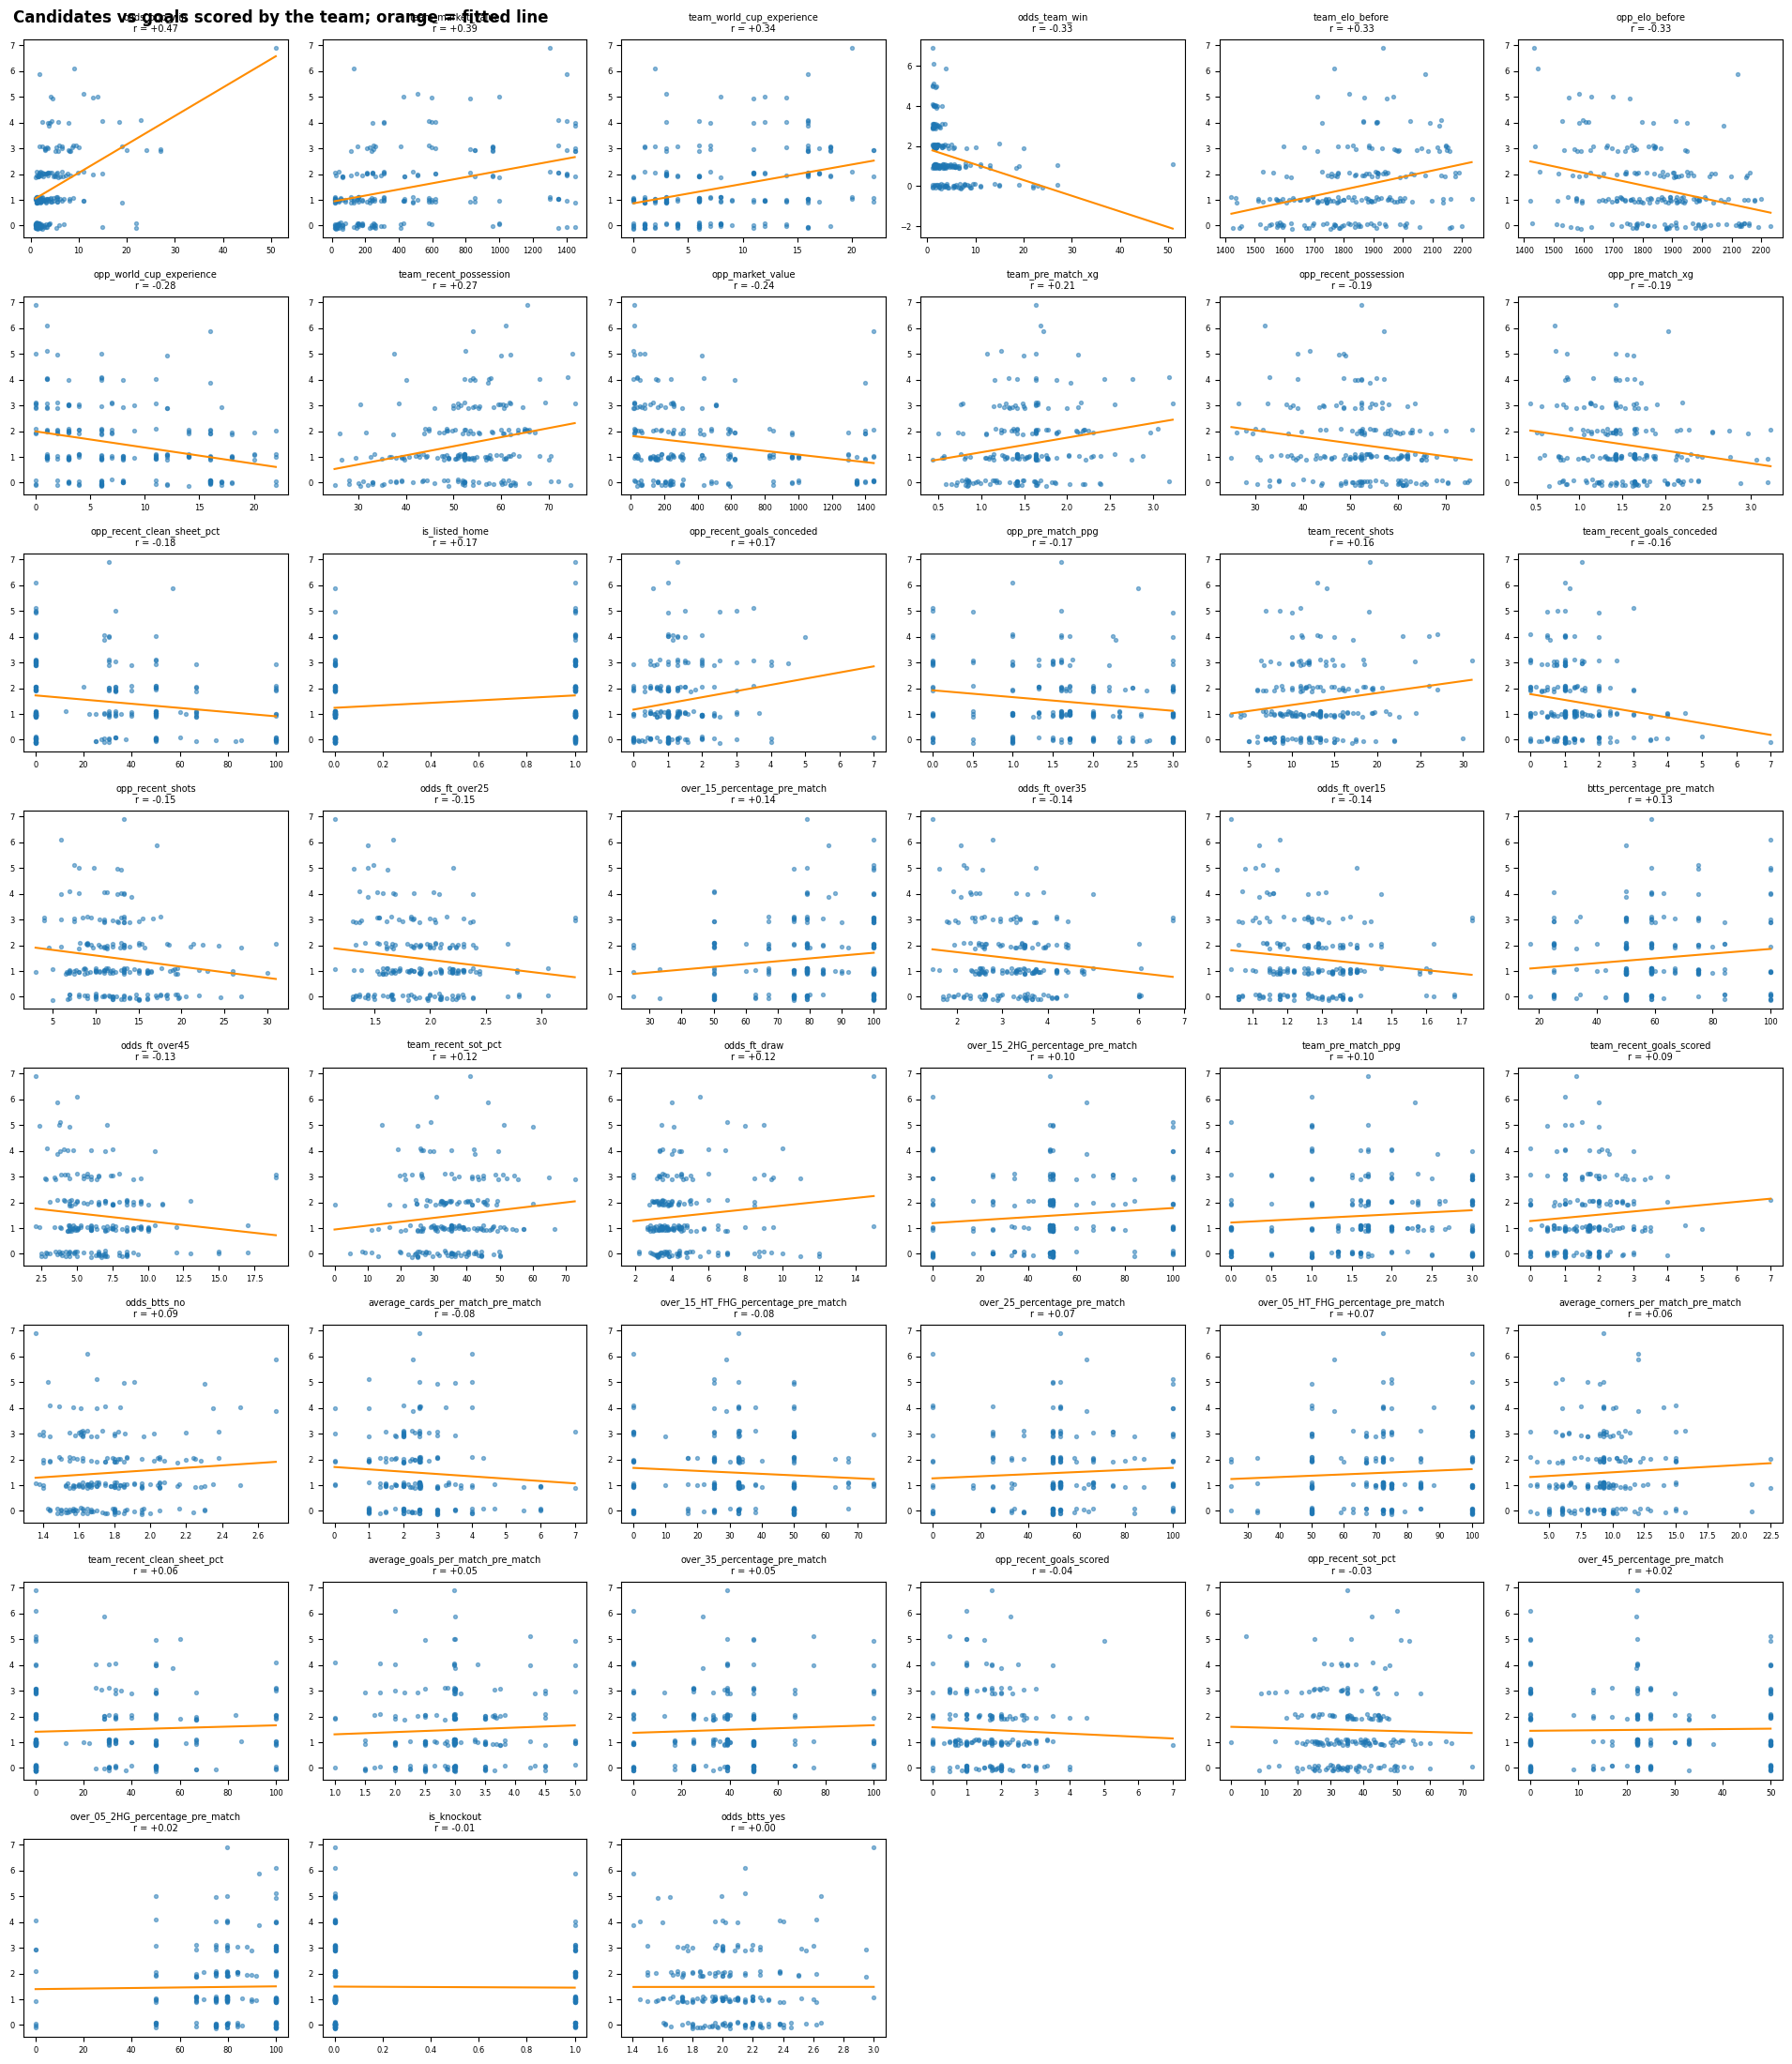

In [ ]:
from scipy import stats
from sklearn.linear_model import LinearRegression

# expected sign of the correlation with goals_scored by the team, written BEFORE looking at the data.
# 0 = no clear direction (e.g. a scoring-environment variable shared by both teams)
team_sign = {'recent_goals_scored': +1, 'recent_shots': +1, 'recent_sot_pct': +1, 'recent_possession': +1,
             'elo_before': +1, 'market_value': +1, 'world_cup_experience': +1, 'pre_match_ppg': +1, 'pre_match_xg': +1}
opp_sign = {'recent_goals_conceded': +1, 'recent_clean_sheet_pct': -1, 'recent_possession': -1,
            'elo_before': -1, 'market_value': -1, 'world_cup_experience': -1, 'pre_match_ppg': -1}
def expected_sign(c):
    if c.startswith('team_'): return team_sign.get(c[5:], 0)
    if c.startswith('opp_'):  return opp_sign.get(c[4:], 0)
    return {'odds_team_win': -1, 'odds_opp_win': +1, 'is_listed_home': +1, 'is_knockout': -1}.get(c, 0)

rows = []
for c in candidates.columns:
    r, p = stats.pearsonr(candidates[c], target)
    s = expected_sign(c)
    rows.append({'variable': c, 'expected sign': {1: '+', -1: '-', 0: '?'}[s], 'pearson r': r, 'p-value': p,
                 'sign as expected': (np.sign(r) == s) if s != 0 else None})
eda = pd.DataFrame(rows).set_index('variable').sort_values('pearson r', key=abs, ascending=False)
display(eda.round(4))
signed = eda['sign as expected'].dropna()
print("Hypotheses with an expected sign confirmed by the sign of r:", int(signed.astype(bool).sum()), "of", len(signed))

# scatter plots with fitted line (small vertical jitter because goals are whole numbers), strongest first
n = len(eda); ncols = 6; nrows = int(np.ceil(n / ncols))
jit = np.random.RandomState(0).uniform(-.12, .12, len(target))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows)); axes = axes.flatten()
for ax, c in zip(axes, eda.index):
    ax.scatter(candidates[c], target + jit, s=8, alpha=.5)
    b = np.polyfit(candidates[c], target, 1); xs = np.linspace(candidates[c].min(), candidates[c].max(), 20)
    ax.plot(xs, np.polyval(b, xs), color='darkorange', lw=1.5)
    ax.set_title(f"{c}\nr = {eda.loc[c, 'pearson r']:+.2f}", fontsize=7); ax.tick_params(labelsize=6)
for ax in axes[n:]: ax.axis('off')
plt.suptitle('Candidates vs goals scored by the team; orange = fitted line', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

SELECTED (8): ['odds_opp_win', 'team_market_value', 'team_world_cup_experience', 'odds_team_win', 'team_elo_before', 'opp_elo_before', 'opp_world_cup_experience', 'team_recent_possession']
Highest VIF in the selected set: 4.85


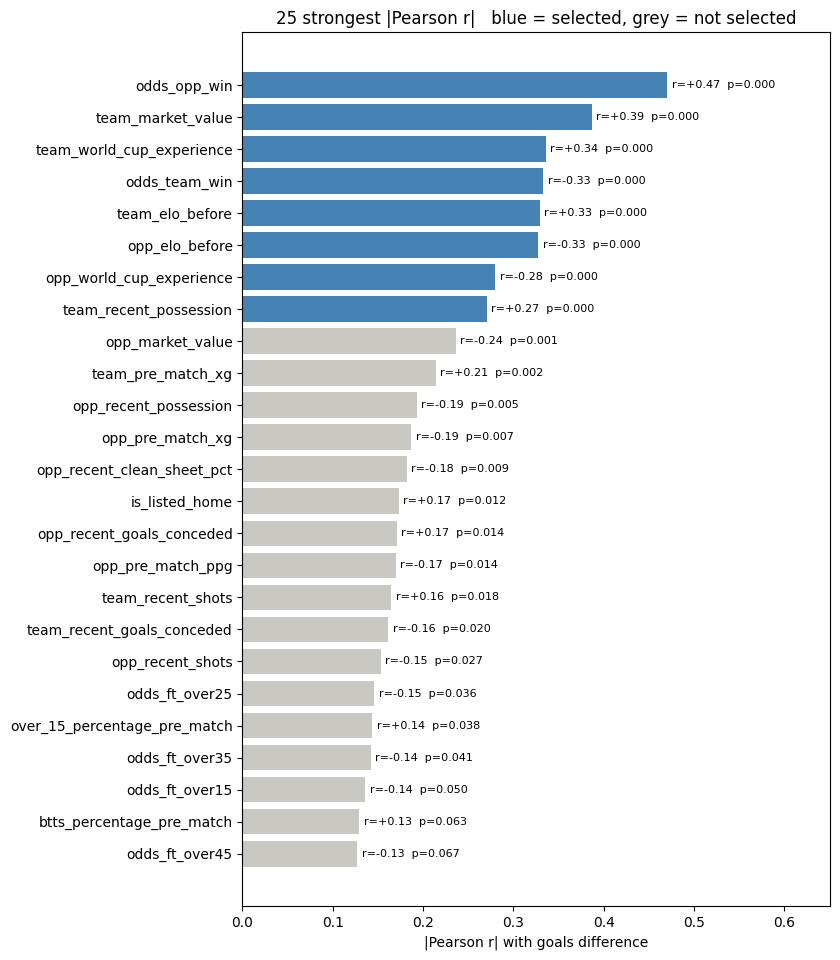

In [ ]:
def max_vif(X):
    """Largest variance-inflation factor in X (inf if a column is an exact copy of the others)."""
    out = []
    for c in X.columns:
        others = X.drop(columns=c)
        r2 = LinearRegression().fit(others, X[c]).score(others, X[c])
        out.append(np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2))
    return max(out)

def select_top_k(X, tab, k=8, vif_limit=10):
    chosen = []
    for c in tab.index:                                   # strongest |r| first
        if len(chosen) == k: break
        if chosen and max_vif(X[chosen + [c]]) >= vif_limit: continue   # would create serious multicollinearity
        chosen.append(c)
    return chosen

selected_features = select_top_k(candidates, eda, k=8, vif_limit=10)

print("SELECTED (8):", selected_features)
print("Highest VIF in the selected set: %.2f" % max_vif(candidates[selected_features]))

# bar chart of the 25 strongest |r|: blue = selected
t = eda.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, .34 * len(t) + 1.2))
ax.barh(t.index, t['pearson r'].abs(), color=['steelblue' if v in selected_features else '#c9c8c2' for v in t.index])
for i, (r_, p_) in enumerate(zip(t['pearson r'], t['p-value'])):
    ax.text(abs(r_) + .005, i, f'r={r_:+.2f}  p={p_:.3f}', va='center', fontsize=8)
ax.set(title='25 strongest |Pearson r|   blue = selected, grey = not selected', xlabel='|Pearson r| with goals difference')
ax.set_xlim(0, t['pearson r'].abs().max() + .18)
plt.tight_layout(); plt.show()

## Train / test split (80% / 20%)

We split **first**, before any optimisation. Every step below is *fitted on the training set only*
(outlier bounds, Yeo-Johnson lambdas, scaler mean/std) and then *applied* to the test set,
so the test set never influences the model. The test set is never filtered, so every stage is scored on the same 20% of matches.

Each match contributes two rows (one per team) that share the same match conditions, so the split is done **by match**: both rows of a match always go to the same side. Otherwise one team's row could be in training while its opponent's row from the same match is in the test set, which would leak information.

In [ ]:
feature_cols = selected_features   # the 8 variables nominated by the EDA above

from sklearn.model_selection import GroupShuffleSplit
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
                           .split(df_final, groups=df_final['match_id']))
X_train, X_test = df_final.loc[train_idx, feature_cols], df_final.loc[test_idx, feature_cols]
y_train, y_test = df_final.loc[train_idx, 'goals_scored'], df_final.loc[test_idx, 'goals_scored']

print("Train:", X_train.shape, " Test:", X_test.shape)

# ---- helpers ----
def print_equation(model, target_name):
    equation = f"{target_name} = {model.params['const']:.4f}"
    for variable in model.params.index:
        if variable == 'const':
            continue
        coefficient = model.params[variable]
        if coefficient >= 0:
            equation += f" + {coefficient:.4f} ({variable})"
        else:
            equation += f" - {abs(coefficient):.4f} ({variable})"
    print("\nRegression equation:")
    print(equation)

results = []   # one row per optimisation stage

def fit_and_evaluate(stage, X_tr, y_tr, X_te, y_te):
    """Fit OLS on the (current) training data, score on train and on the untouched test set."""
    model = sm.OLS(y_tr, sm.add_constant(X_tr, has_constant='add')).fit()
    pred_tr = model.predict(sm.add_constant(X_tr, has_constant='add'))
    pred_te = model.predict(sm.add_constant(X_te, has_constant='add'))
    results.append({
        'Stage': stage,
        'Train R2': r2_score(y_tr, pred_tr),
        'Test R2': r2_score(y_te, pred_te),
        'Test RMSE': np.sqrt(mean_squared_error(y_te, pred_te)),
        'Test MAE': mean_absolute_error(y_te, pred_te),
    })
    return model, pred_te

# ---- Baseline (no optimisation) ----
model, _ = fit_and_evaluate('0. Baseline', X_train, y_train, X_test, y_test)
print_equation(model, 'Goals Scored')

Train: (166, 8)  Test: (42, 8)

Regression equation:
Goals Scored = 3.9107 + 0.0572 (odds_opp_win) + 0.0011 (team_market_value) - 0.0079 (team_world_cup_experience) - 0.0087 (odds_team_win) - 0.0005 (team_elo_before) - 0.0014 (opp_elo_before) - 0.0012 (opp_world_cup_experience) + 0.0070 (team_recent_possession)


## Optimization 1: Remove outliers (training set only)

In [ ]:
Q1 = y_train.quantile(0.25)
Q3 = y_train.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

mask = (y_train >= lower_bound) & (y_train <= upper_bound)

X_train_cur = X_train[mask].copy()
y_train_cur = y_train[mask].copy()
X_test_cur  = X_test.copy()

print("Training observations after removing outliers:", len(X_train_cur), f"(removed {(~mask).sum()})")

model, _ = fit_and_evaluate('1. + Outlier removal', X_train_cur, y_train_cur, X_test_cur, y_test)
print_equation(model, "Goals Scored")

Training observations after removing outliers: 151 (removed 15)

Regression equation:
Goals Scored = 0.3602 + 0.0328 (odds_opp_win) + 0.0003 (team_market_value) - 0.0098 (team_world_cup_experience) + 0.0023 (odds_team_win) + 0.0010 (team_elo_before) - 0.0007 (opp_elo_before) - 0.0235 (opp_world_cup_experience) + 0.0059 (team_recent_possession)


## Optimization 2: Check for non-linear relationships

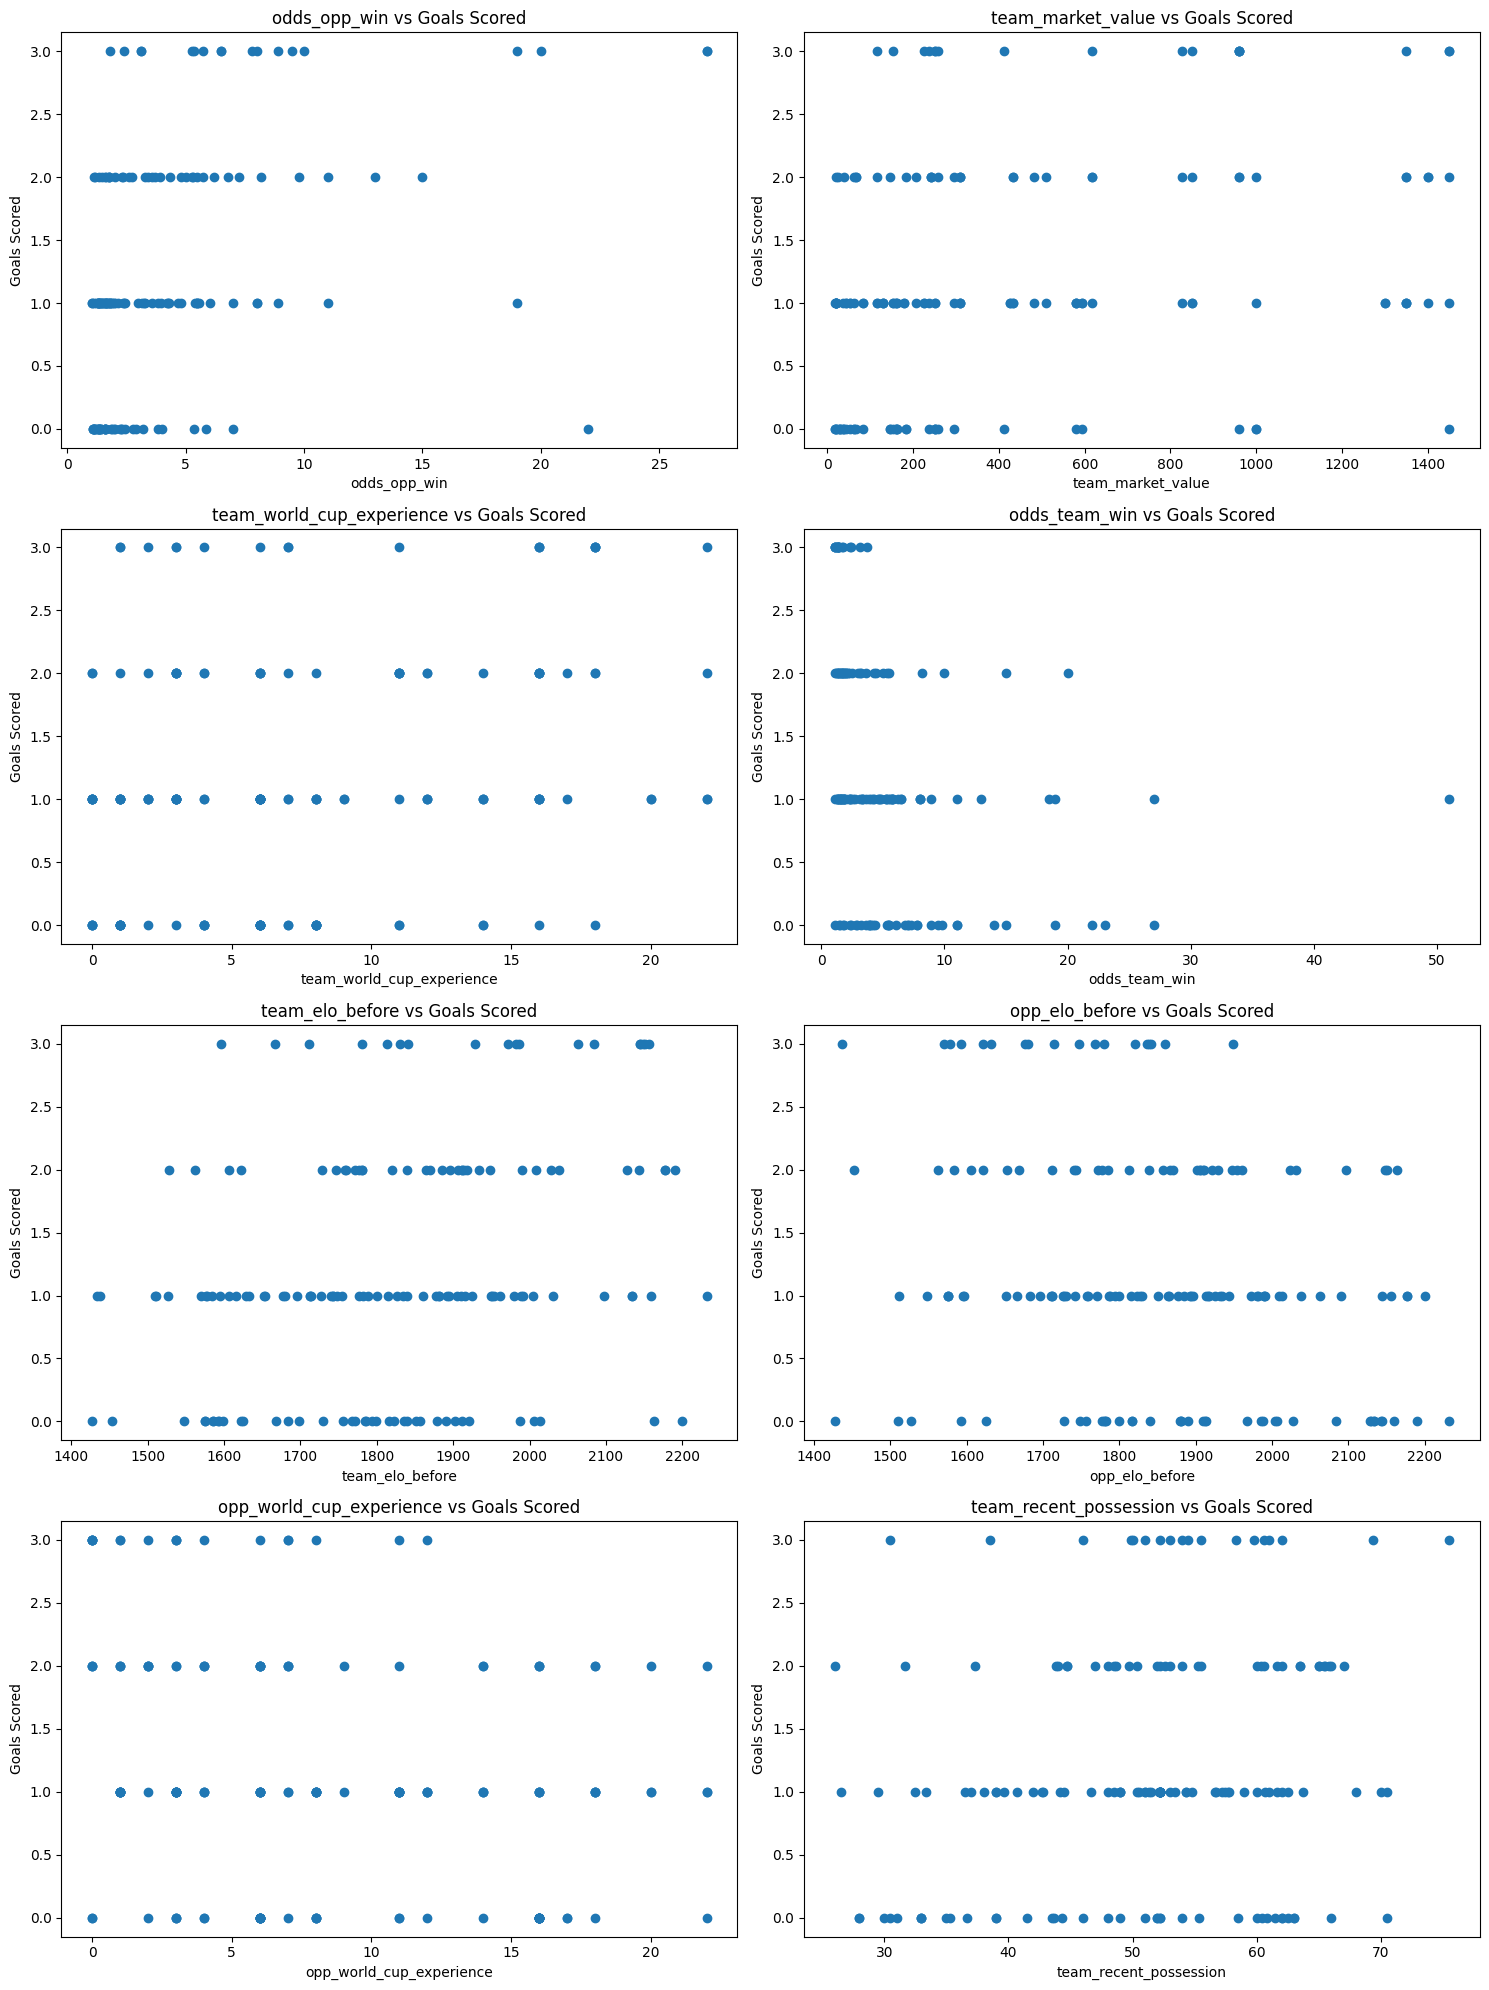

In [ ]:
fig, axes = plt.subplots(int(np.ceil(len(feature_cols) / 2)), 2, figsize=(15, 5 * int(np.ceil(len(feature_cols) / 2))))

for ax, variable in zip(axes.flatten(), feature_cols):
    ax.scatter(X_train_cur[variable], y_train_cur)
    ax.set_xlabel(variable)
    ax.set_ylabel('Goals Scored')
    ax.set_title(f'{variable} vs Goals Scored')

plt.tight_layout()
plt.show()

Goals are whole numbers, so every plot is a set of horizontal bands of points. None shows a clear curve: the relationships are weak and roughly straight. The two bookmaker-odds variables are strongly skewed (and their rank correlation with goals is a little different from the straight-line r), which the Yeo-Johnson step below handles. So we add no extra non-linear terms.

In [ ]:
# Decision: no non-linear transformation needed, so the data passes through unchanged.
model, _ = fit_and_evaluate('2. + Non-linear check (no change)', X_train_cur, y_train_cur, X_test_cur, y_test)

## Optimization 3: Check for multicollinearity

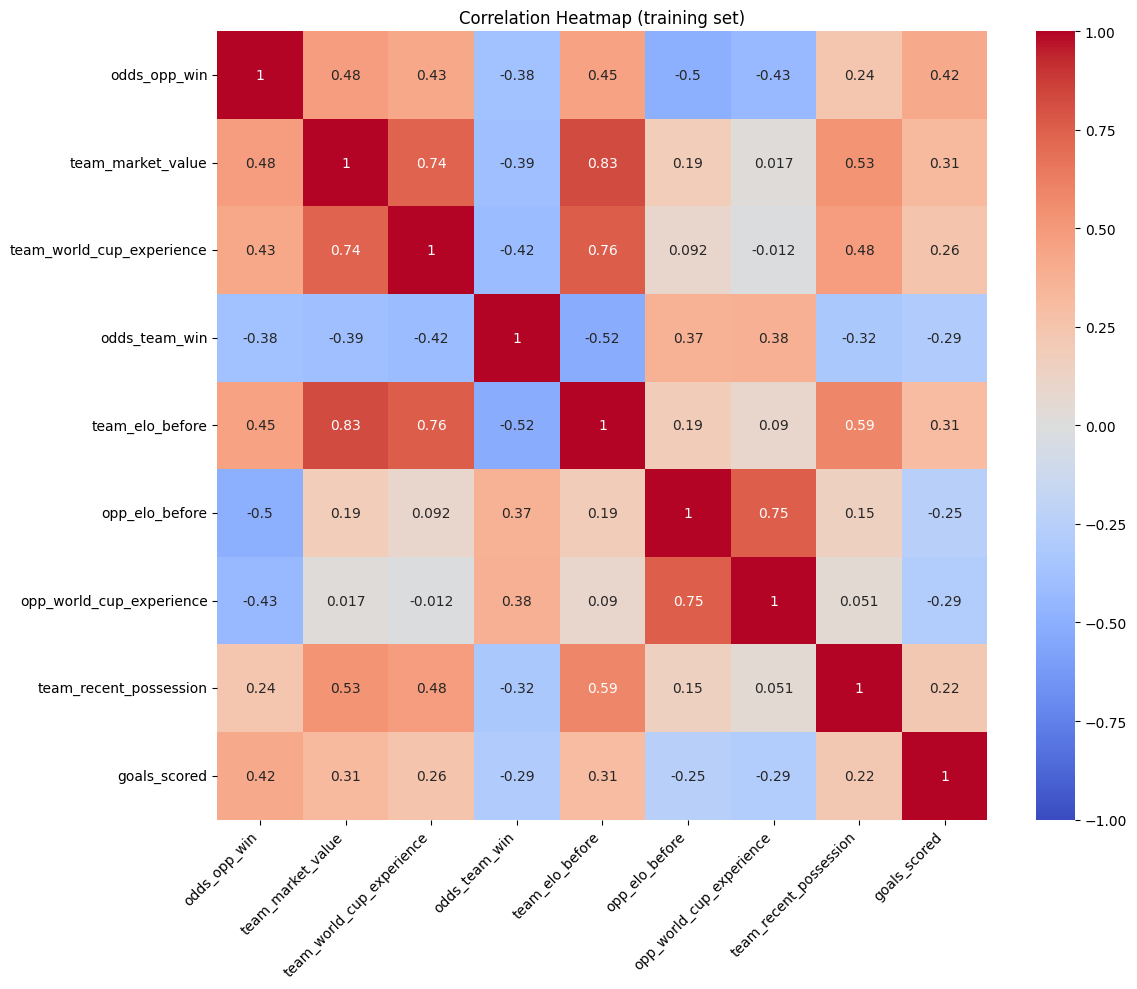

Highest pairwise correlation between features: 0.827


In [ ]:
corr_df = pd.concat([X_train_cur, y_train_cur], axis=1)

plt.figure(figsize=(12, 10))
sns.heatmap(corr_df.corr(), vmin=-1, vmax=1, center=0, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap (training set)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

feat_corr = X_train_cur.corr().abs().where(~np.eye(len(feature_cols), dtype=bool))
print("Highest pairwise correlation between features:", round(feat_corr.max().max(), 3))

The strongest correlation between two features is printed above (about 0.83). It is high, because Elo, market value, World Cup experience and the bookmaker odds all measure team strength, but the highest VIF in the selected set is 4.9, well below the limit of 10 used in the selection. We therefore keep all eight variables. The individual coefficients of these correlated variables should be read with care.

In [ ]:
model, _ = fit_and_evaluate('3. + Multicollinearity check', X_train_cur, y_train_cur, X_test_cur, y_test)

## Optimization 4: Gaussian transformation (Yeo-Johnson)

In [ ]:
X_train_before_yj = X_train_cur.copy()
yj = PowerTransformer(method='yeo-johnson', standardize=False)

X_train_cur = pd.DataFrame(yj.fit_transform(X_train_cur),
                           index=X_train_cur.index, columns=X_train_cur.columns)
X_test_cur  = pd.DataFrame(yj.transform(X_test_cur),
                           index=X_test_cur.index, columns=X_test_cur.columns)

skew_before = X_train_before_yj.skew()
skew_after  = X_train_cur.skew()

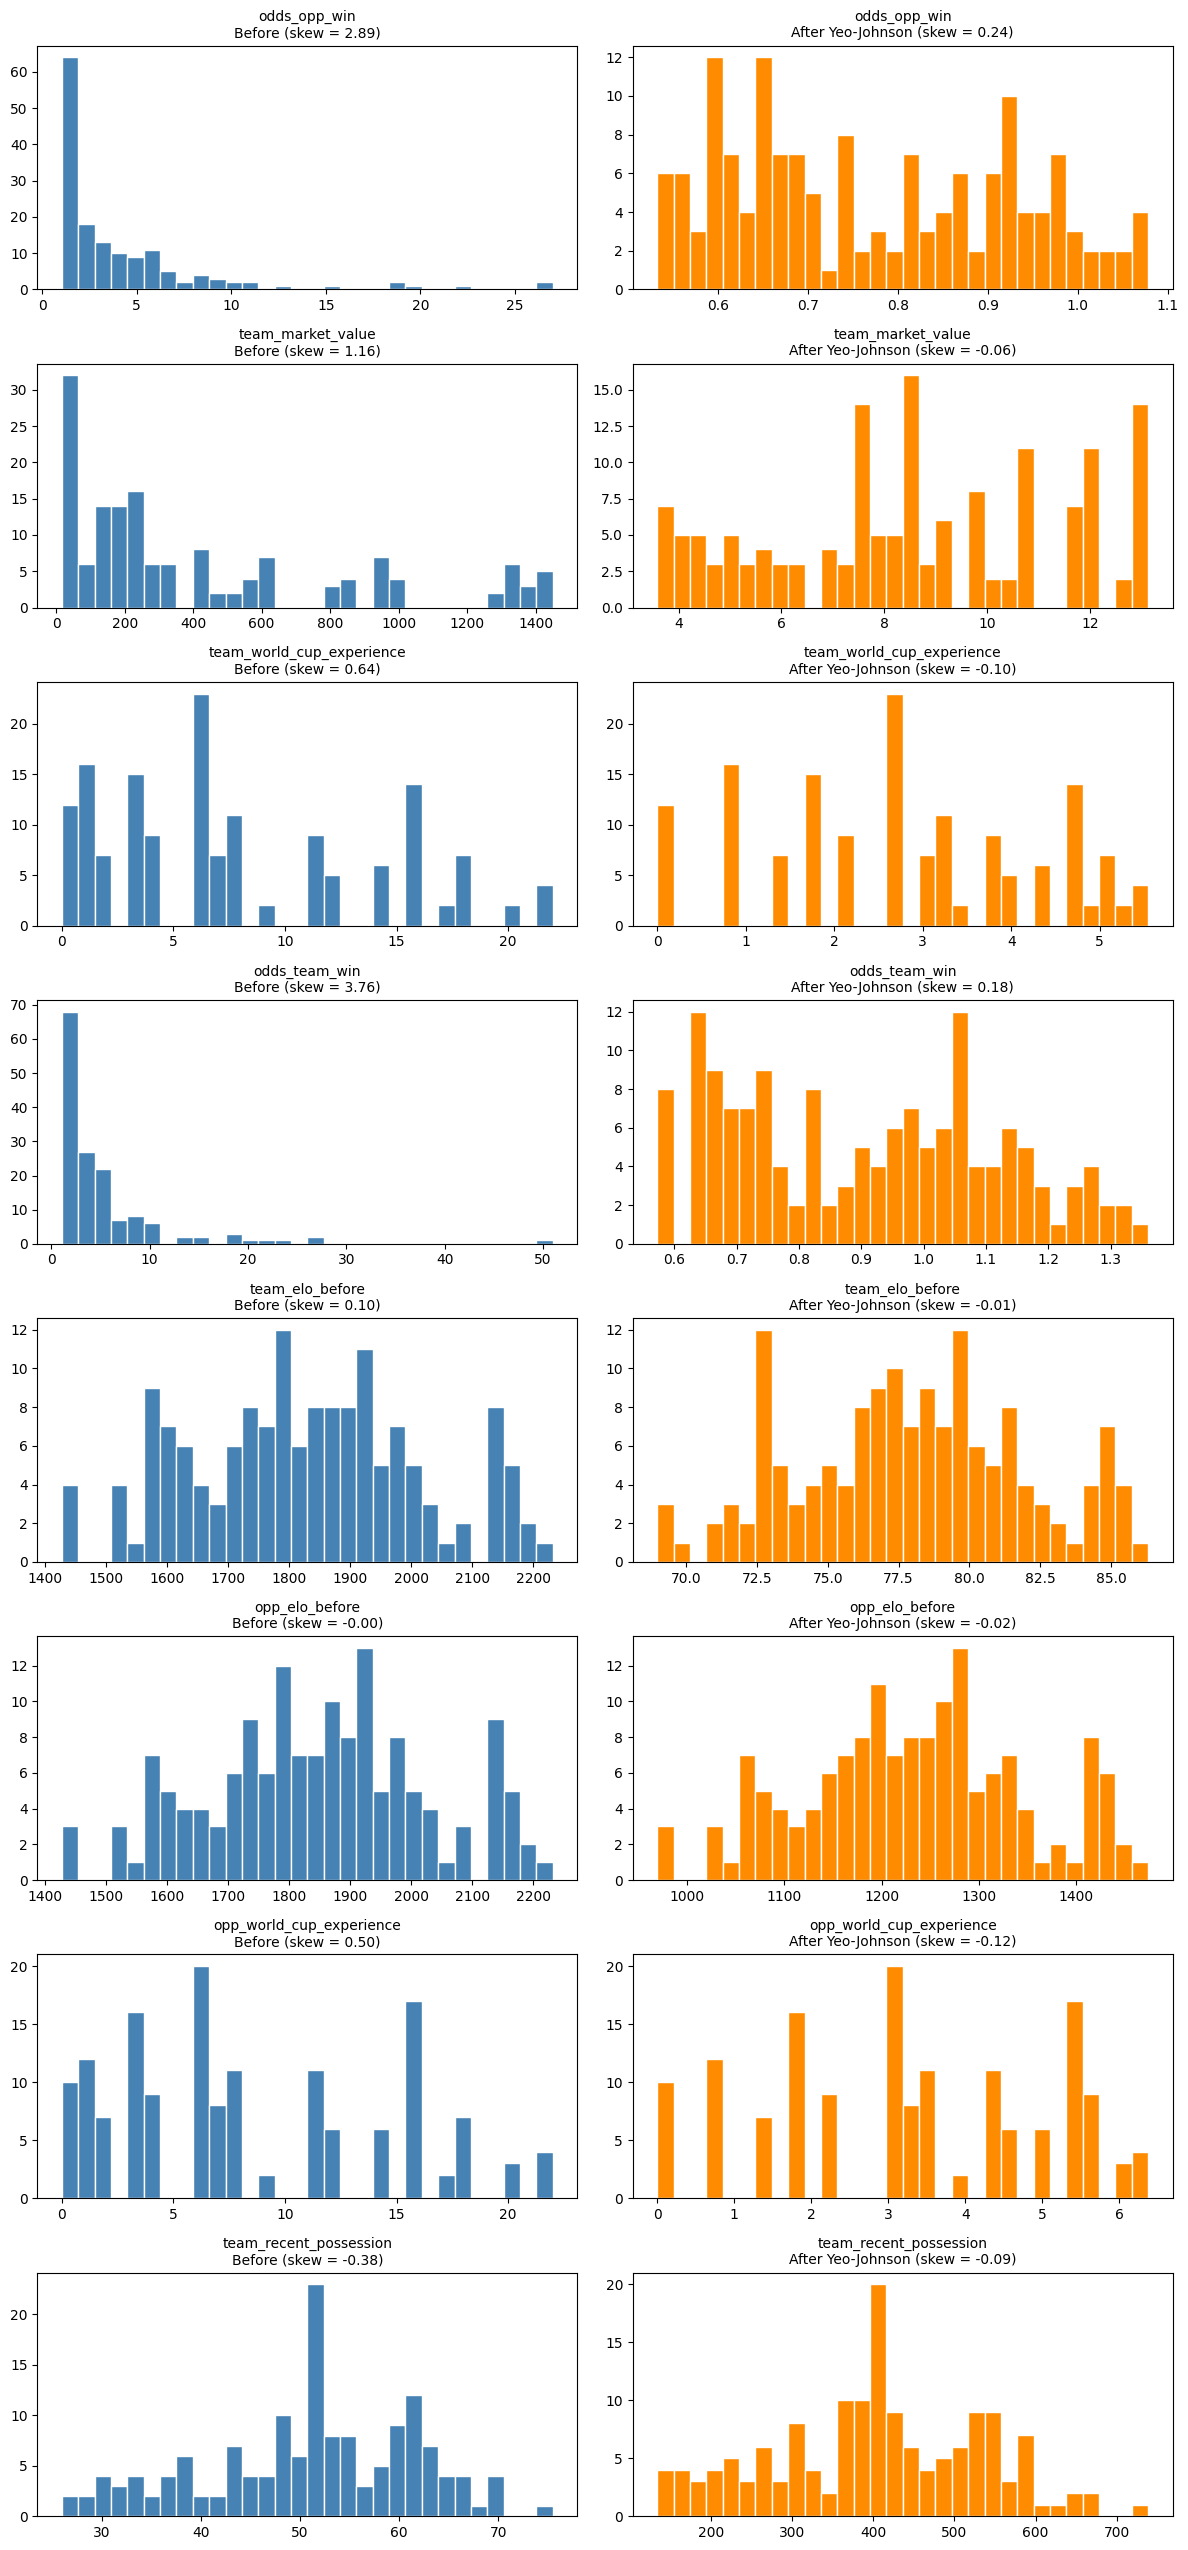

In [ ]:
# --------------------------------------------------
# HISTOGRAM OF EVERY VARIABLE: BEFORE vs AFTER YEO-JOHNSON
# --------------------------------------------------
fig, axes = plt.subplots(len(feature_cols), 2, figsize=(12, 3.2 * len(feature_cols)))

for i, var in enumerate(feature_cols):
    axes[i, 0].hist(X_train_before_yj[var], bins=30, color='steelblue', edgecolor='white')
    axes[i, 0].set_title(f'{var}\nBefore (skew = {skew_before[var]:.2f})', fontsize=10)

    axes[i, 1].hist(X_train_cur[var], bins=30, color='darkorange', edgecolor='white')
    axes[i, 1].set_title(f'{var}\nAfter Yeo-Johnson (skew = {skew_after[var]:.2f})', fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
model, _ = fit_and_evaluate('4. + Yeo-Johnson', X_train_cur, y_train_cur, X_test_cur, y_test)
print_equation(model, "Goals Scored")


Regression equation:
Goals Scored = -0.7828 + 1.9437 (odds_opp_win) + 0.0700 (team_market_value) - 0.1096 (team_world_cup_experience) - 0.4254 (odds_team_win) + 0.0015 (team_elo_before) + 0.0005 (opp_elo_before) - 0.0767 (opp_world_cup_experience) + 0.0002 (team_recent_possession)


## Optimization 5: Z-standardisation

In [ ]:
zs = StandardScaler()

X_train_cur = pd.DataFrame(zs.fit_transform(X_train_cur),
                           index=X_train_cur.index, columns=X_train_cur.columns)
X_test_cur  = pd.DataFrame(zs.transform(X_test_cur),
                           index=X_test_cur.index, columns=X_test_cur.columns)

final_model, final_pred_te = fit_and_evaluate('5. + Z-standardisation', X_train_cur, y_train_cur, X_test_cur, y_test)
print_equation(final_model, "Goals Scored")


Regression equation:
Goals Scored = 1.2053 + 0.3006 (odds_opp_win) + 0.1958 (team_market_value) - 0.1714 (team_world_cup_experience) - 0.0889 (odds_team_win) + 0.0060 (team_elo_before) + 0.0566 (opp_elo_before) - 0.1359 (opp_world_cup_experience) + 0.0316 (team_recent_possession)


## Test-set evaluation of the final model

,Train R2,Test R2,Test RMSE,Test MAE
Stage,,,,
0. Baseline,0.3318,0.1615,1.3673,0.9888
1. + Outlier removal,0.2336,0.1724,1.3583,1.0159
2. + Non-linear check (no change),0.2336,0.1724,1.3583,1.0159
3. + Multicollinearity check,0.2336,0.1724,1.3583,1.0159
4. + Yeo-Johnson,0.2687,0.1854,1.3477,1.0426
5. + Z-standardisation,0.2687,0.1854,1.3477,1.0426


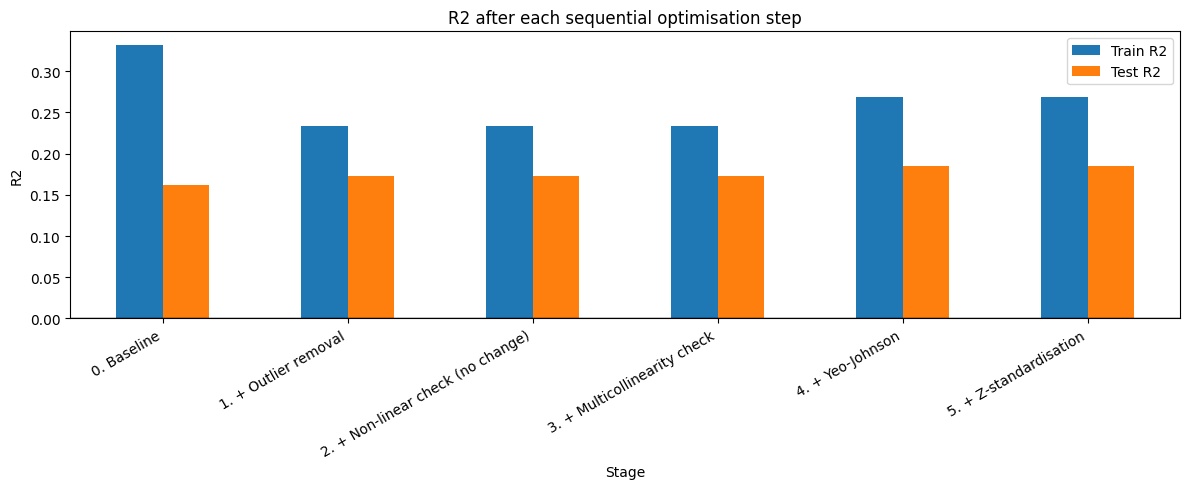

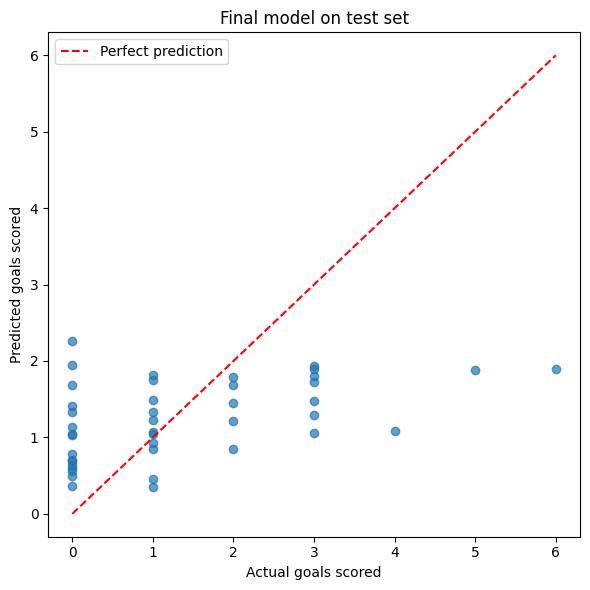

                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                         1.2053      0.069     17.528      0.000       1.069       1.341
odds_opp_win                  0.3006      0.345      0.870      0.386      -0.382       0.983
team_market_value             0.1958      0.163      1.203      0.231      -0.126       0.517
team_world_cup_experience    -0.1714      0.116     -1.482      0.140      -0.400       0.057
odds_team_win                -0.0889      0.370     -0.240      0.811      -0.820       0.642
team_elo_before               0.0060      0.167      0.036      0.971      -0.324       0.336
opp_elo_before                0.0566      0.175      0.323      0.747      -0.290       0.403
opp_world_cup_experience     -0.1359      0.114     -1.190      0.236      -0.362       0.090
team_recent_possession        0.0316      0.088      0.358  

In [ ]:
results_df = pd.DataFrame(results).set_index('Stage').round(4)
display(results_df)

# R2 per stage (train vs test)
results_df[['Train R2', 'Test R2']].plot(kind='bar', figsize=(12, 5))
plt.axhline(0, color='black', linewidth=1)
plt.title('R2 after each sequential optimisation step')
plt.ylabel('R2')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

# Final model: predicted vs actual on the 20% test set
plt.figure(figsize=(6, 6))
plt.scatter(y_test, final_pred_te, alpha=0.7)
lims = [min(y_test.min(), final_pred_te.min()), max(y_test.max(), final_pred_te.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual goals scored')
plt.ylabel('Predicted goals scored')
plt.title('Final model on test set')
plt.legend()
plt.tight_layout()
plt.show()

print(final_model.summary().tables[1])

## Comparison with other scikit-learn regression models

The final OLS model is compared with other regressors from scikit-learn. Every model gets **exactly the same data**: the fully optimised training set (outliers removed, Yeo-Johnson, z-standardisation) and the same untouched 20% test set. A mean-only `DummyRegressor` shows what "no skill" looks like, and a `PoissonRegressor` is included because goals are small counts. The cross-validation keeps both rows of a match in the same fold. The **CV RMSE is measured on the training rows that remain after outlier removal** (the high-scoring rows were removed), so it is lower than the test RMSE and is only meant to compare the models with each other.

In [ ]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.linear_model import PoissonRegressor

models = {
    'Mean baseline (no skill)': DummyRegressor(),
    'Poisson regression': PoissonRegressor(alpha=1e-3, max_iter=1000),
    'Ridge': RidgeCV(alphas=np.logspace(-2, 3, 30)),
    'Lasso': LassoCV(cv=5, random_state=42, max_iter=20000),
    'Elastic Net': ElasticNetCV(cv=5, random_state=42, max_iter=20000),
    'Random forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42),
    'Gradient boosting': GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=42),
    'Support vector (RBF)': SVR(kernel='rbf', C=1.0),
    'k-nearest neighbours (k=10)': KNeighborsRegressor(n_neighbors=10),
}

gkf = GroupKFold(n_splits=5)                                   # both rows of a match stay in the same fold
groups_train = df_final.loc[X_train_cur.index, 'match_id']
rows, preds = [], {}
for name, est in models.items():
    m = clone(est).fit(X_train_cur, y_train_cur)
    pred_tr, pred_te = m.predict(X_train_cur), m.predict(X_test_cur)
    cv_rmse = -cross_val_score(clone(est), X_train_cur, y_train_cur, cv=gkf, groups=groups_train, scoring='neg_root_mean_squared_error').mean()
    preds[name] = pred_te
    rows.append({'Model': name, 'Train R2': r2_score(y_train_cur, pred_tr), 'Test R2': r2_score(y_test, pred_te),
                 'Test RMSE': np.sqrt(mean_squared_error(y_test, pred_te)), 'Test MAE': mean_absolute_error(y_test, pred_te)})

# the statsmodels OLS from the optimisation steps, for reference
rows.append({'Model': 'OLS (statsmodels, final model above)', 'Train R2': results[-1]['Train R2'], 'Test R2': results[-1]['Test R2'],
             'Test RMSE': results[-1]['Test RMSE'], 'Test MAE': results[-1]['Test MAE']})

comparison = pd.DataFrame(rows).set_index('Model').sort_values('Test RMSE').round(4)
display(comparison)

,Train R2,Test R2,Test RMSE,Test MAE
Model,,,,
Ridge,0.2551,0.2058,1.3307,1.0215
Lasso,0.2445,0.2035,1.3326,1.0275
Elastic Net,0.2460,0.2029,1.3331,1.0266
"OLS (statsmodels, final model above)",0.2687,0.1854,1.3477,1.0426
Poisson regression,0.2742,0.1719,1.3588,1.0436
Random forest,0.7263,0.1656,1.3640,1.0637
Support vector (RBF),0.4412,0.1306,1.3923,1.0176
k-nearest neighbours (k=10),0.3372,0.1149,1.4048,1.0571
Gradient boosting,0.6874,0.0832,1.4297,1.0824


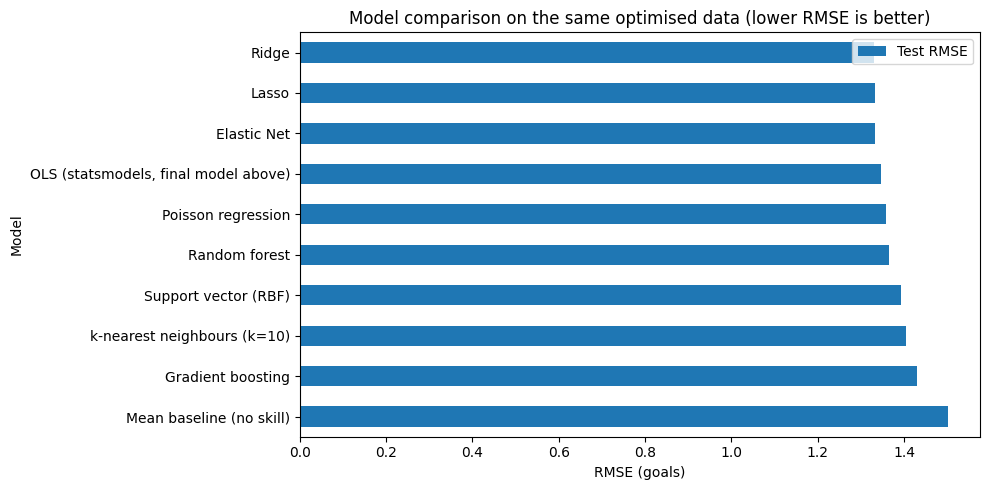

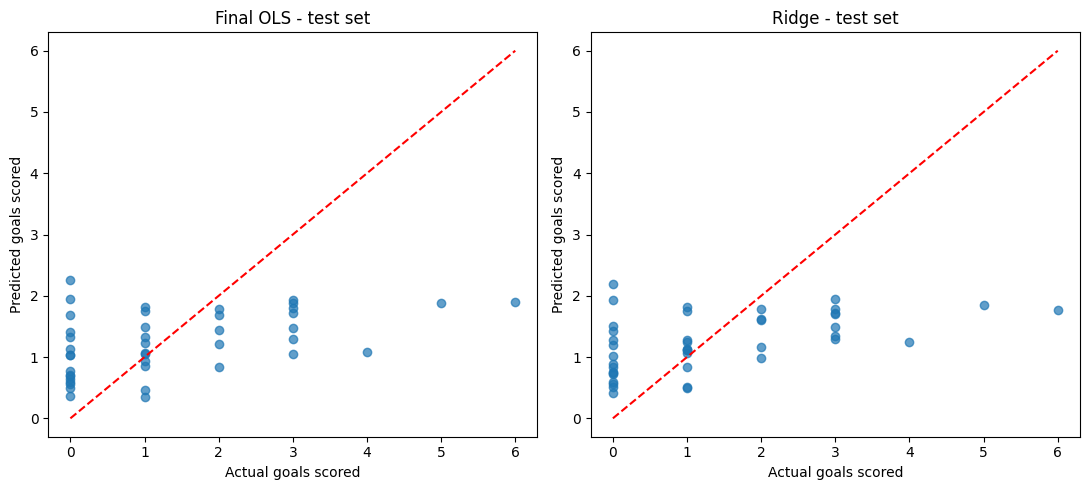

Best competing model on the test set: Ridge


In [ ]:
# Test RMSE and cross-validated RMSE per model (lower is better)
plot_df = comparison[['Test RMSE']].iloc[::-1]
plot_df.plot(kind='barh', figsize=(10, 5))
plt.title('Model comparison on the same optimised data (lower RMSE is better)')
plt.xlabel('RMSE (goals)')
plt.tight_layout()
plt.show()

# Predicted vs actual on the 20% test set for the best model and the final OLS
best_name = comparison.drop(index=['OLS (statsmodels, final model above)', 'Mean baseline (no skill)'])['Test RMSE'].idxmin()
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (title, p) in zip(axes, [('Final OLS', final_pred_te), (best_name, preds[best_name])]):
    ax.scatter(y_test, p, alpha=0.7)
    lims = [min(y_test.min(), np.min(p)), max(y_test.max(), np.max(p))]
    ax.plot(lims, lims, 'r--')
    ax.set(title=f'{title} - test set', xlabel='Actual goals scored', ylabel='Predicted goals scored')
plt.tight_layout()
plt.show()
print("Best competing model on the test set:", best_name)

**Conclusion.** The 8 variables chosen by the EDA from the 45 variables available before the match are `odds_opp_win`, `team_market_value`, `team_world_cup_experience`, `odds_team_win`, `team_elo_before`, `opp_elo_before`, `opp_world_cup_experience` and `team_recent_possession`: team-strength measures (bookmaker odds, squad value, Elo, World Cup experience) and one form variable. None of them is shared by name with Linear Regression 2.1; counted by the raw statistic behind them, the two models share 4 (Elo, market value, World Cup experience and bookmaker odds), which is within the limit of 4.

* On the 42 unseen test rows (21 matches) the model explains about 16% of the variance before the transformations and about 19% at the end (RMSE ≈ 1.35 goals against 1.50 for the mean-only guess). Goals in a single match are very noisy, so a low R² is expected.
* Outlier removal drops the 15 training rows where the team scored 4 or more goals. The test set is not filtered, so the test scores stay comparable across the stages. The non-linear and multicollinearity checks change nothing (highest VIF 4.9, below 10).
* Yeo-Johnson improves the test R² a little (about 0.17 to 0.19); z-standardisation does not change the fit, it only puts the coefficients on a comparable scale.
* **Comparison with other scikit-learn models:** Ridge, Lasso and Elastic Net are slightly better than plain OLS on the test set (R² about 0.20 against 0.19, RMSE about 1.33 against 1.35), Poisson regression is about equal to OLS, and Random Forest, SVR, k-nearest neighbours and Gradient Boosting are worse (Random Forest and Gradient Boosting fit the training set closely, R² 0.73 and 0.69, but do not generalise). All models beat the mean-only baseline, but the differences between them are small compared with the noise of a 42-row test set.